# AOD-4. Анализ изображений Bird и Drone
[Источник данных](https://data.mendeley.com/datasets/cd5z895tr2/1). Единицы анализа — фотография и рамка объекта.

In [13]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns
from PIL import Image
from IPython.display import display

## 1. Исходные изображения и разбиение на выборки
Каждая строка первой таблицы — отдельный файл фотографии. Колонки описывают его расположение и размер на диске. Сами пиксели прочитаем при проверке качества. В папке Annotations лежат разные варианты записи рамок для этих же фотографий.

In [14]:
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
dataset = root / "data/raw/aod4/AOD 4"
image_dir = dataset / "Images"
annotation_dir = dataset / "Annotations"
sns.set_theme(style="whitegrid")
splits = sorted(p.name for p in image_dir.iterdir() if p.is_dir())
records = []
for split in splits:
    for path in sorted((image_dir / split).iterdir()):
        if path.is_file():
            records.append(
                (split, path.name, path.suffix.lower(), path.stat().st_size)
            )

files = pd.DataFrame(records, columns=["split", "file_name", "extension", "bytes"])
print("Папки выборок:", splits)
print(
    "Форматы разметки:",
    sorted(p.name for p in annotation_dir.iterdir() if p.is_dir()),
)
print("Форматы файлов изображений:", files.extension.unique())
print("Строк и столбцов:", files.shape, "| Столбцы:", files.columns.tolist())
display(files.head(3))
files.info()
display(files.groupby("split").size().rename("фотографий").to_frame())

Папки выборок: ['test', 'train', 'valid']
Форматы разметки: ['COCO Annotation format', 'PASCAL VOC Annotation format', 'TF Record Annotation format', 'YOLOv8 OBB format', 'YOLOv8 format']
Форматы файлов изображений: <StringArray>
['.jpg']
Length: 1, dtype: str
Строк и столбцов: (22516, 4) | Столбцы: ['split', 'file_name', 'extension', 'bytes']


,split,file_name,extension,bytes
0,test,20190925_101846_1_1_000_jpg.rf.497f3eb572bec39...,.jpg,33429
1,test,20190925_101846_1_1_004_jpg.rf.0c12b3a3cad8a8c...,.jpg,32848
2,test,20190925_101846_1_1_012_jpg.rf.650837209d9799f...,.jpg,35991


<class 'pandas.DataFrame'>
RangeIndex: 22516 entries, 0 to 22515
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   split      22516 non-null  str  
 1   file_name  22516 non-null  str  
 2   extension  22516 non-null  str  
 3   bytes      22516 non-null  int64
dtypes: int64(1), str(3)
memory usage: 703.8 KB


,фотографий
split,
test,2241
train,15761
valid,4514


## 2. Загрузка аннотаций, классы и рамки объектов
Берём формат COCO. В JSON каждой выборки есть три списка: `images` описывает кадры, `categories` расшифровывает номера классов, `annotations` содержит по одной строке на объект. Поле `bbox` хранит четыре числа в пикселях: левый край, верхний край, ширину и высоту. Для связи используем **split и image_id вместе**, поскольку в разных выборках номера могут повторяться.

In [15]:
frames, objects, categories = [], [], []
for s in splits:
    coco = json.loads(
        (
            annotation_dir / "COCO Annotation format" / s / "_annotations.coco.json"
        ).read_text()
    )
    frame = pd.DataFrame(coco["images"])[["id", "file_name", "width", "height"]]
    frames.append(frame.rename(columns={"id": "image_id"}).assign(split=s))
    cats = pd.DataFrame(coco["categories"])[["id", "name"]]
    categories.append(cats.assign(split=s))
    ann = pd.DataFrame(coco["annotations"])[
        ["id", "image_id", "category_id", "bbox"]
    ]
    ann["label"] = ann.category_id.map(cats.set_index("id").name).fillna("unknown")
    objects.append(ann.assign(split=s))
images = pd.concat(frames, ignore_index=True)
boxes = pd.concat(objects, ignore_index=True)
key = ["split", "image_id"]
for name, table in [("Записи изображений", images), ("Рамки объектов", boxes)]:
    print(
        name,
        "· строк и столбцов:",
        table.shape,
        "· столбцы:",
        table.columns.tolist(),
    )
    display(table.head(3))
display(pd.concat(categories).pivot(index="id", columns="split", values="name"))
print("Классов с размеченными объектами:", boxes.label.nunique())
display(boxes.label.value_counts().rename("число рамок").to_frame())

Записи изображений · строк и столбцов: (22516, 5) · столбцы: ['image_id', 'file_name', 'width', 'height', 'split']


,image_id,file_name,width,height,split
0,0,yt-K2kVdKb8gco-0015_jpg.rf.01d6f3b918c757581be...,1024,1024,test
1,1,yt-5KOIhxSH7lw-0307_jpg.rf.02ba2dee5e3b3420807...,1024,1024,test
2,2,V_DRONE_043153_278_png_jpg.rf.02d4454fac7097a5...,1024,1024,test


Рамки объектов · строк и столбцов: (31598, 6) · столбцы: ['id', 'image_id', 'category_id', 'bbox', 'label', 'split']


,id,image_id,category_id,bbox,label,split
0,0,0,2,"[484, 266, 106.5, 157]",bird,test
1,1,1,4,"[419, 387, 133, 144.5]",helicopter,test
2,2,2,3,"[497, 790, 34, 38]",drone,test


split,test,train,valid
id,,,
0,airplane-helicopter-drone-bird,airplane-helicopter-drone-bird,airplane-helicopter-drone-bird
1,airplane,airplane,airplane
2,bird,bird,bird
3,drone,drone,drone
4,helicopter,helicopter,helicopter


Классов с размеченными объектами: 4


,число рамок
label,
bird,7900
helicopter,7900
airplane,7900
drone,7898


В справочнике пять строк. Категория 0 обозначает родительскую группу. Собственные рамки есть у четырёх классов: airplane, bird, drone и helicopter.

## 3. Отбор кадров Bird и Drone
Берём кадр, если хотя бы один объект размечен и **каждая** его рамка относится к bird или drone. Если рядом с птицей есть самолёт, исключаем весь кадр. В таблице ниже доля кадров считается от всех записей изображений **той же выборки**, доля объектов — от всех рамок этой выборки.

In [16]:
labels = boxes.groupby(key).label.agg(frozenset)
images = images.join(labels.rename("labels"), on=key)
keep = images.labels.map(
    lambda x: isinstance(x, frozenset) and bool(x) and x <= {"bird", "drone"}
)
candidates = images.loc[keep].copy()
candidate_boxes = boxes.merge(candidates[key], on=key, validate="many_to_one")
summary = pd.DataFrame(
    {
        "все кадры": images.groupby("split").size(),
        "отобрано кадров": candidates.groupby("split").size(),
        "все объекты": boxes.groupby("split").size(),
        "отобрано объектов": candidate_boxes.groupby("split").size(),
    }
)
summary.loc["всего"] = summary.sum()
summary["% кадров"] = 100 * summary["отобрано кадров"] / summary["все кадры"]
summary["% объектов"] = 100 * summary["отобрано объектов"] / summary["все объекты"]
display(summary.round(2))

,все кадры,отобрано кадров,все объекты,отобрано объектов,% кадров,% объектов
split,,,,,,
test,2241,1062,3171,1617,47.39,50.99
train,15761,7444,22058,11018,47.23,49.95
valid,4514,2121,6369,3155,46.99,49.54
всего,22516,10627,31598,15790,47.20,49.97


## 4. Проверка пропусков и очистка
Проверяем весь набор, включая записи без единой рамки. Сверяем имена файлов, полностью читаем фотографии и сравниваем фактические размеры с COCO. Отдельно ищем нулевые, нечитаемые и однотонные изображения. Доли считаем от числа записей того типа, который проверяем.

In [17]:
# Имена нужны для поиска всех рамок одной фотографии.
named_boxes = candidate_boxes.merge(candidates[key + ["file_name"]], on=key)
boxes_by_file = named_boxes.groupby(["split", "file_name"]).bbox.agg(list)


def background_brightness(gray, rectangles, width, height):
    """Медиана яркости вне рамок на уменьшенной копии кадра."""
    rows, cols = gray.shape
    background = np.ones(gray.shape, dtype=bool)
    for x, y, box_width, box_height in rectangles:
        left = max(0, int(np.floor(x * cols / width)))
        right = min(cols, int(np.ceil((x + box_width) * cols / width)))
        top = max(0, int(np.floor(y * rows / height)))
        bottom = min(rows, int(np.ceil((y + box_height) * rows / height)))
        background[top:bottom, left:right] = False

    if background.any():
        return float(np.median(gray[background]))
    return np.nan


quality = []
for row in files.itertuples():
    result = {"read_error": False, "uniform": False}
    try:
        with Image.open(image_dir / row.split / row.file_name) as im:
            im.load()
            result.update(w=im.width, h=im.height, format=im.format, mode=im.mode)
            rgb = im if im.mode == "RGB" else im.convert("RGB")
            result["uniform"] = all(lo == hi for lo, hi in rgb.getextrema())
            gray = np.asarray(im.resize((128, 128)).convert("L"))
            result.update(brightness=gray.mean(), contrast=gray.std())
            rectangles = boxes_by_file.get((row.split, row.file_name))
            if rectangles is not None:
                result["background_level"] = background_brightness(
                    gray, rectangles, im.width, im.height
                )
    except (OSError, ValueError):
        result["read_error"] = True
    quality.append(result)
files = files[["split", "file_name", "extension", "bytes"]].join(
    pd.DataFrame(quality)
)
audit = images.merge(
    files,
    on=["split", "file_name"],
    how="outer",
    indicator=True,
    validate="one_to_one",
)
missing_file = audit._merge.eq("left_only")
unlisted = audit._merge.eq("right_only")
no_boxes = ~unlisted & audit.labels.isna()
size_conflict = (
    audit._merge.eq("both")
    & audit.read_error.eq(False)
    & ((audit.w != audit.width) | (audit.h != audit.height))
)
orphans = boxes.merge(
    images[key], on=key, how="left", indicator=True, validate="many_to_one"
)
checks = [
    ("Кадры COCO без рамок", no_boxes.sum(), len(images)),
    ("Кадры COCO без файла фото", missing_file.sum(), len(images)),
    ("Файлы без записи COCO", unlisted.sum(), len(files)),
    ("Файлы нулевого размера", files.bytes.eq(0).sum(), len(files)),
    ("Нечитаемые файлы", files.read_error.sum(), len(files)),
    ("Однотонные изображения", files.uniform.sum(), len(files)),
    ("Размер расходится с COCO", size_conflict.sum(), len(images)),
    ("Рамки без записи кадра", orphans._merge.eq("left_only").sum(), len(boxes)),
]
report = pd.DataFrame(checks, columns=["проверка", "количество", "от чего считаем"])
report["%"] = (100 * report["количество"] / report["от чего считаем"]).round(3)
display(report)

,проверка,количество,от чего считаем,%
0,Кадры COCO без рамок,596,22516,2.647
1,Кадры COCO без файла фото,0,22516,0.000
2,Файлы без записи COCO,0,22516,0.000
3,Файлы нулевого размера,0,22516,0.000
4,Нечитаемые файлы,0,22516,0.000
5,Однотонные изображения,1,22516,0.004
6,Размер расходится с COCO,0,22516,0.000
7,Рамки без записи кадра,0,31598,0.000


In [18]:
usable = (
    audit._merge.eq("both")
    & audit.read_error.eq(False)
    & audit.uniform.eq(False)
    & ~size_conflict
)
clean = candidates.merge(
    audit.loc[
        usable, key + ["w", "h", "brightness", "contrast", "background_level"]
    ],
    on=key,
    validate="one_to_one",
)
clean["group"] = clean.labels.map(lambda x: " + ".join(sorted(x)))
objects_clean = boxes.merge(clean[key + ["w", "h"]], on=key, validate="many_to_one")
print("Целевых кадров до очистки:", len(candidates), "| после:", len(clean))
print("Исключено при проверке файлов:", len(candidates) - len(clean))
print("Объектов осталось:", len(objects_clean))

Целевых кадров до очистки: 10627 | после: 10627
Исключено при проверке файлов: 0
Объектов осталось: 15790


Кадр без рамок может содержать только фон. Он не подходит под условие отбора, поэтому уже исключён на шаге 3. Показатели яркости и контраста сохраняем для описания выборки. Тёмный фон сам по себе не служит причиной удаления.

### Яркость кадра и фона
Для кадра считаем среднюю яркость и контраст (стандартное отклонение) на серой копии 128 × 128. Для фона берём медиану пикселей за пределами всех рамок. Шкала от 0 до 255. Для сравнения делим её на три равных интервала. Это условные группы яркости: светлый фон возможен и ночью при искусственном освещении.

фон,тёмный,средний,светлый,нет фона
group,,,,
bird,225,1672,1306,0
bird + drone,0,0,5,0
drone,2133,4842,444,0
всего,2358,6514,1755,0


фон,тёмный,средний,светлый,нет фона
group,,,,
bird,7.0,52.2,40.8,0.0
bird + drone,0.0,0.0,100.0,0.0
drone,28.8,65.3,6.0,0.0
всего,22.2,61.3,16.5,0.0


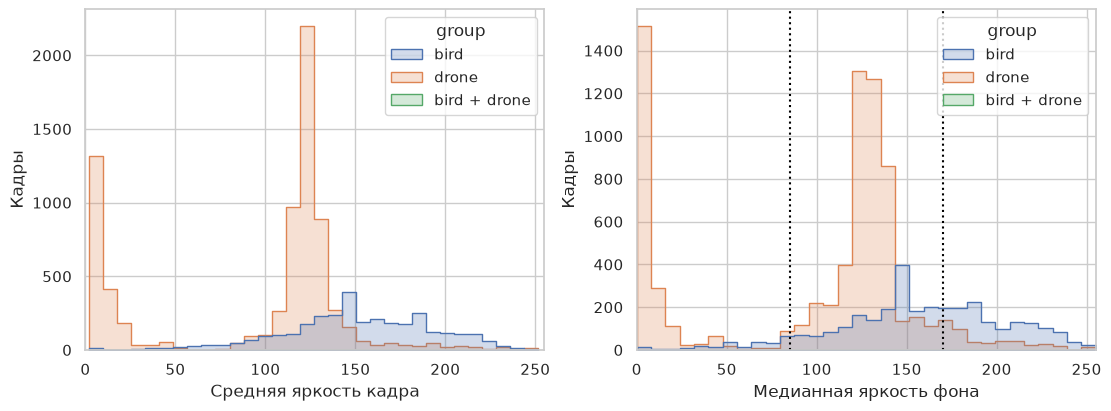

In [19]:
levels = ["тёмный", "средний", "светлый"]
clean["фон"] = pd.cut(
    clean.background_level, bins=[0, 85, 170, 256], labels=levels, right=False
)
background_group = clean["фон"].cat.add_categories("нет фона").fillna("нет фона")
light_counts = pd.crosstab(clean.group, background_group).reindex(
    columns=levels + ["нет фона"], fill_value=0
)
light_counts.loc["всего"] = light_counts.sum()
display(light_counts)
display(light_counts.div(light_counts.sum(axis=1), axis=0).mul(100).round(1))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for axis, metric, title in zip(
    axes,
    ["brightness", "background_level"],
    ["Средняя яркость кадра", "Медианная яркость фона"],
):
    sns.histplot(data=clean, x=metric, hue="group", bins=32, element="step", ax=axis)
    axis.set(xlabel=title, ylabel="Кадры", xlim=(0, 255))
for boundary in (85, 170):
    axes[1].axvline(boundary, color="black", linestyle=":")
plt.show()

## 5. Состав классов и число объектов на фото

group,bird,drone,bird + drone
split,,,
test,320,742,0
train,2247,5193,4
valid,636,1484,1
всего,3203,7419,5


label,bird,drone,все объекты
объектов на одном фото,,,
0,7419,3203,0
1,2115,7312,9417
2,419,48,472
3,106,17,123
4,106,17,123
5,92,3,95
6,108,5,113
7,49,0,49
8,38,0,38


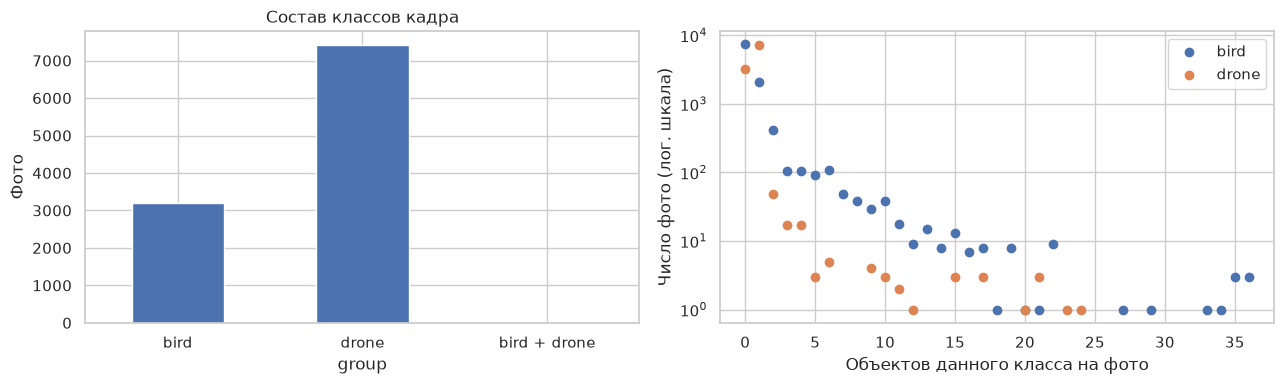

In [20]:
groups = ["bird", "drone", "bird + drone"]
composition = pd.crosstab(clean.split, clean.group).reindex(
    columns=groups, fill_value=0
)
composition.loc["всего"] = composition.sum()
display(composition)
per_photo = objects_clean.groupby(key + ["label"]).size().unstack(fill_value=0)
per_photo["все объекты"] = per_photo.sum(axis=1)
# Каждая колонка считает фото среди всех отобранных кадров, включая ноль объектов данного класса.
freq = per_photo.apply(pd.Series.value_counts).fillna(0).astype(int).sort_index()
freq.index.name = "объектов на одном фото"
display(freq)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
composition.loc["всего"].plot.bar(
    ax=ax[0], rot=0, ylabel="Фото", title="Состав классов кадра"
)
for label in ["bird", "drone"]:
    nonzero = freq[label][freq[label] > 0]
    ax[1].scatter(nonzero.index, nonzero, label=label)
ax[1].set(xlabel="Объектов данного класса на фото", ylabel="Число фото (лог. шкала)")
ax[1].set_yscale("log")
ax[1].legend()
plt.tight_layout()
plt.show()

## 6. Размеры и площадь фотографий и рамок
Ширину и высоту измеряем в пикселях, площадь — в квадратных пикселях. Доля площади кадра позволяет оценить масштаб объекта. Сначала проверяем размеры и границы каждой рамки, чтобы ошибочные координаты не искажали распределения.

,,,кадров
w,h,frame_area,
1024,1024,1048576,10627


brightness                                                  \
                  count   mean   std    min    25%    50%    75%    max   
group                                                                     
bird             3203.0  151.3  41.2    2.2  128.4  148.8  181.7  251.4   
bird + drone        5.0  207.4   8.8  194.5  205.6  206.3  212.4  218.2   
drone            7419.0   94.6  54.7    3.0   21.0  119.6  125.0  248.7   

             contrast                                             
                count  mean   std   min   25%   50%   75%    max  
group                                                             
bird           3203.0  34.7  19.8   2.2  16.5  35.2  50.0  101.3  
bird + drone      5.0  28.4   7.9  22.4  24.8  26.0  26.8   42.2  
drone          7419.0  26.7  18.6   3.1  10.8  25.2  32.0   94.2

неполные или нечисловые рамки    0
неположительные размеры          0
выход за границу кадра           0
dtype: int64

bw                                                        bh  \
        count     mean      std  min   25%   50%    75%     max   count   
label                                                                     
bird   7892.0  142.281  142.310  0.5  52.0  89.5  177.5   980.0  7892.0   
drone  7898.0   71.709   64.797  7.0  43.5  57.5   77.0  1024.0  7898.0   

                ...      area            area_pct                              \
          mean  ...       75%        max    count   mean    std    min    25%   
label           ...                                                             
bird   145.168  ...  33838.75   669799.0   7892.0  3.447  6.978  0.001  0.246   
drone   69.213  ...   5200.00  1029714.5   7898.0  0.812  4.104  0.009  0.216   

                             
         50%    75%     max  
label                        
bird   0.749  3.227  63.877  
drone  0.317  0.496  98.201  

[2 rows x 32 columns]

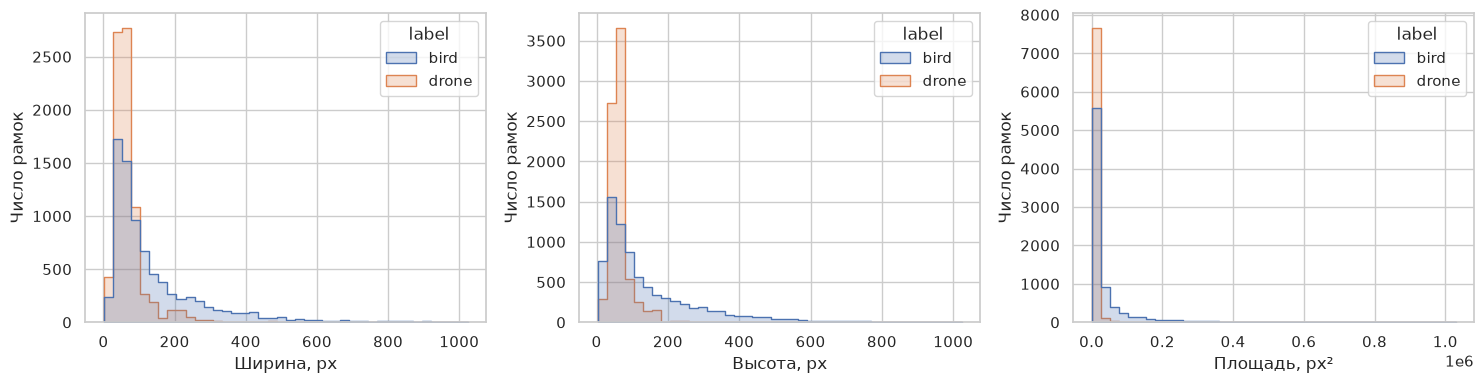

In [21]:
clean["frame_area"] = clean.w * clean.h
display(clean.groupby(["w", "h", "frame_area"]).size().rename("кадров").to_frame())
display(clean.groupby("group")[["brightness", "contrast"]].describe().round(1))
geometry = objects_clean.copy()
coords = pd.DataFrame(
    geometry.bbox.map(
        lambda b: b if isinstance(b, list) and len(b) == 4 else [np.nan] * 4
    ).tolist(),
    columns=["x", "y", "bw", "bh"],
).apply(pd.to_numeric, errors="coerce")
geometry = geometry.join(coords)
finite = np.isfinite(coords).all(axis=1)
positive = (geometry.bw > 0) & (geometry.bh > 0)
inside = (
    (geometry.x >= 0)
    & (geometry.y >= 0)
    & (geometry.x + geometry.bw <= geometry.w + 1e-9)
    & (geometry.y + geometry.bh <= geometry.h + 1e-9)
)
display(
    pd.Series(
        {
            "неполные или нечисловые рамки": (~finite).sum(),
            "неположительные размеры": (finite & ~positive).sum(),
            "выход за границу кадра": (finite & ~inside).sum(),
        }
    )
)
valid = geometry[finite & positive & inside].copy()
valid["area"] = valid.bw * valid.bh
valid["area_pct"] = 100 * valid.area / (valid.w * valid.h)
display(valid.groupby("label")[["bw", "bh", "area", "area_pct"]].describe().round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(
    axes, ["bw", "bh", "area"], ["Ширина, px", "Высота, px", "Площадь, px²"]
):
    sns.histplot(data=valid, x=col, hue="label", element="step", bins=40, ax=ax)
    ax.set(xlabel=title, ylabel="Число рамок")
plt.tight_layout()
plt.show()

### Разброс размеров и площади
Границы ящика — 25-й и 75-й процентили, линия внутри — медиана. Усы доходят до крайних наблюдений в пределах 1,5 межквартильного размаха (IQR) от ящика. Отдельные точки лежат за этими пределами.

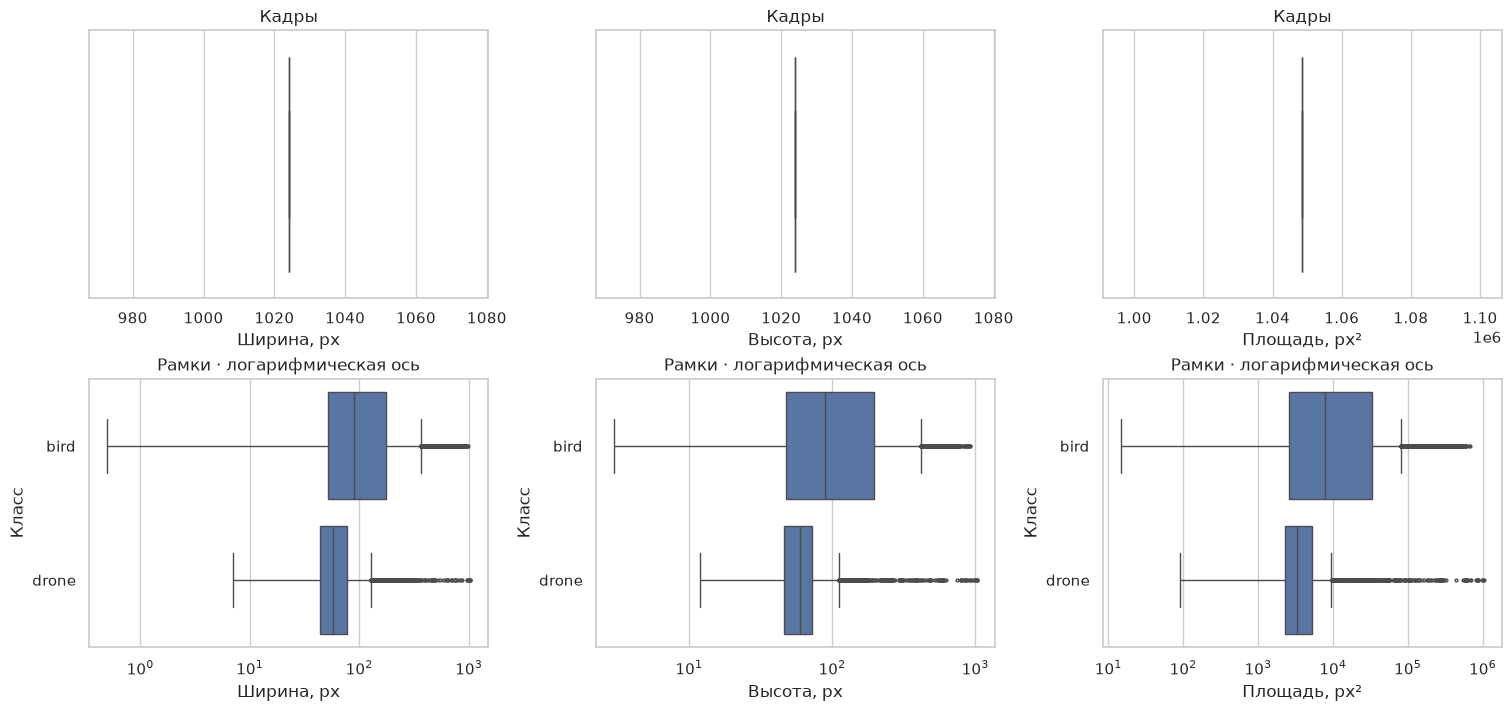

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
metrics = [
    ("w", "bw", "Ширина, px"),
    ("h", "bh", "Высота, px"),
    ("frame_area", "area", "Площадь, px²"),
]
for column, (photo_metric, box_metric, unit) in enumerate(metrics):
    photo_axis, box_axis = axes[:, column]
    sns.boxplot(data=clean, x=photo_metric, ax=photo_axis)
    photo_axis.set(title="Кадры", xlabel=unit)
    sns.boxplot(data=valid, x=box_metric, y="label", ax=box_axis, fliersize=2)
    box_axis.set(title="Рамки · логарифмическая ось", xlabel=unit, ylabel="Класс")
    box_axis.set_xscale("log")
plt.show()

У всех кадров ширина и высота равны 1024 px, площадь — 1 048 576 px². Медиана, квартили и концы усов совпадают, поэтому каждый ящик в верхнем ряду виден как одна линия. Для рамок ось растянута логарифмически после расчёта квартилей и усов в исходных единицах.

In [23]:
quartiles = valid.groupby("label").area.quantile([0.25, 0.5, 0.75]).unstack()
quartiles.columns = ["Q1", "медиана", "Q3"]
iqr = quartiles.Q3 - quartiles.Q1

lower = quartiles.Q1 - 1.5 * iqr
upper = quartiles.Q3 + 1.5 * iqr
outside = (valid.area < valid.label.map(lower)) | (
    valid.area > valid.label.map(upper)
)

thresholds = quartiles.copy()
thresholds["IQR"] = iqr
thresholds["нижний расчётный порог, px²"] = lower
thresholds["верхний расчётный порог, px²"] = upper
thresholds["рамок за порогами"] = outside.groupby(valid.label).sum()
display(thresholds.round(1))

,Q1,медиана,Q3,IQR,"нижний расчётный порог, px²","верхний расчётный порог, px²",рамок за порогами
label,,,,,,,
bird,2584.1,7856.5,33838.8,31254.6,-44297.8,80720.7,971
drone,2268.0,3328.0,5200.0,2932.0,-2130.0,9598.0,866


Нижний расчётный порог равен Q1 − 1,5 × IQR. У обоих классов 1,5 × IQR больше Q1, поэтому порог отрицательный. Площадь каждой проверенной рамки положительна. Все отмеченные рамки (971 у птиц и 866 у дронов) превышают верхний порог. Большая рамка может соответствовать объекту вблизи камеры, поэтому сохраняем её для анализа.

## 7. Примеры фотографий с рамками
Показываем по одному воспроизводимому примеру каждого состава классов. На изображении рисуем все рамки кадра.

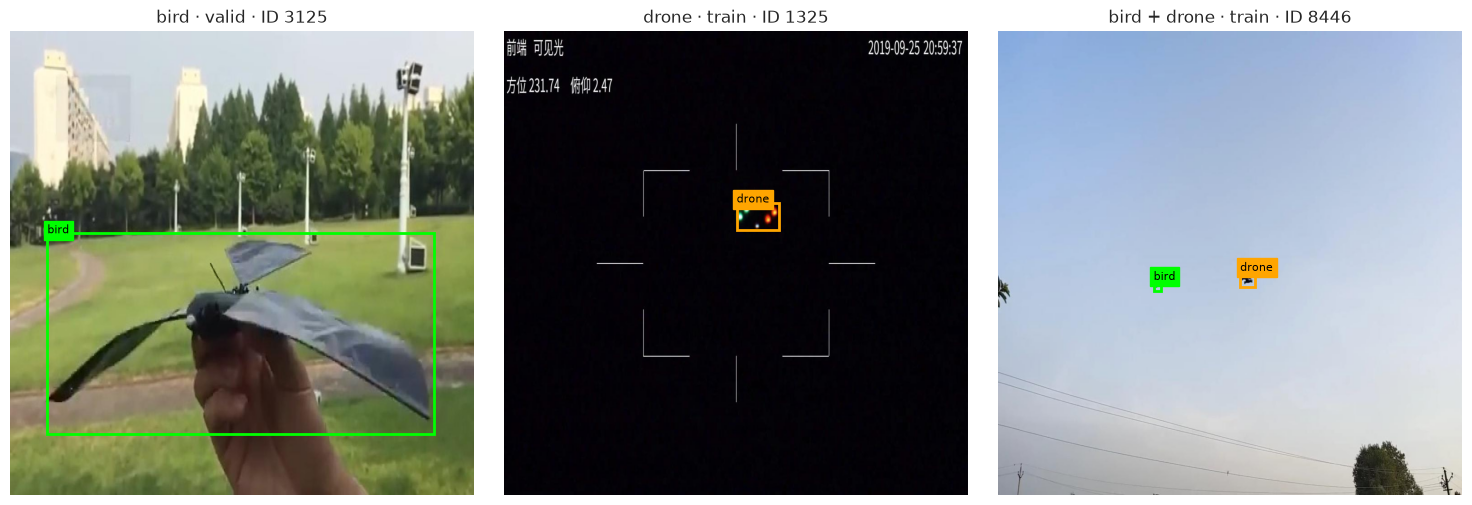

In [24]:
colors = {"bird": "lime", "drone": "orange"}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, groups):
    ax.axis("off")
    subset = clean[clean.group.eq(name)]
    if subset.empty:
        ax.set_title(f"{name}: нет кадров")
        continue
    row = subset.sample(1, random_state=42).iloc[0]
    with Image.open(image_dir / row.split / row.file_name) as im:
        ax.imshow(im)
    marks = valid[(valid.split == row.split) & (valid.image_id == row.image_id)]
    for b in marks.itertuples():
        ax.add_patch(
            Rectangle(
                (b.x, b.y), b.bw, b.bh, fill=False, edgecolor=colors[b.label], lw=2
            )
        )
        ax.text(
            b.x,
            b.y,
            b.label,
            color="black",
            backgroundcolor=colors[b.label],
            fontsize=8,
        )
    ax.set_title(f"{name} · {row.split} · ID {row.image_id}")
plt.tight_layout()
plt.show()

## 8. Положение объектов в кадре
Для каждой рамки вычисляем центр относительно ширины и высоты фотографии. На картах начало координат сверху слева. Сравним центр (средняя половина по каждой оси) с четырьмя углами вместе: обе зоны занимают по 25% площади кадра.

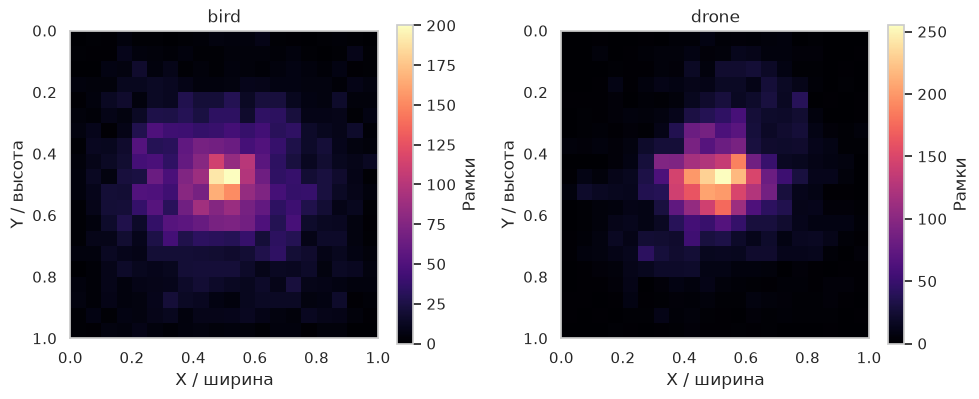

col_0,боковые области,углы,центр
label,,,
bird,27.8,6.9,65.3
drone,18.1,2.4,79.4


In [25]:
valid["cx"] = (valid.x + valid.bw / 2) / valid.w
valid["cy"] = (valid.y + valid.bh / 2) / valid.h
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label in zip(axes, ["bird", "drone"]):
    group = valid[valid.label == label]
    density = ax.hist2d(
        group.cx, group.cy, bins=20, range=[[0, 1], [0, 1]], cmap="magma"
    )
    ax.invert_yaxis()
    ax.set(aspect="equal", title=label, xlabel="X / ширина", ylabel="Y / высота")
    fig.colorbar(density[3], ax=ax, label="Рамки")
plt.tight_layout()
plt.show()
dx, dy = (valid.cx - 0.5).abs(), (valid.cy - 0.5).abs()
zones = np.select(
    [(dx <= 0.25) & (dy <= 0.25), (dx > 0.25) & (dy > 0.25)],
    ["центр", "углы"],
    default="боковые области",
)
display(pd.crosstab(valid.label, zones, normalize="index").mul(100).round(1))

**Выводы.** Из 22 516 кадров отобраны 10 627. На пяти присутствуют оба класса. При почти равном числе рамок кадры только с дронами встречаются чаще: на одном фото может быть несколько птиц. Все фотографии имеют размер 1024 × 1024. Центры рамок сосредоточены ближе к середине: в центральной четверти находятся 65,3% птиц и 79,4% дронов, а в четырёх углах вместе — 6,9% и 2,4%.